# Sesgo medido en los modelos finales e interpretabilidad

En `reports/analisis_sesgo.md` se declararon sesgos (selección, geografía, carácter…). Aquí se **miden en los modelos finales** y se interpreta lo que aprenden:

1. **Error por subgrupo** (sector, carácter, región, SENA, tamaño, historia) frente a la línea base de cada tarea, con IC 95 % por bootstrap sobre IES.
2. **Sensibilidad**: ¿cambian las conclusiones sin Bogotá, con denominador mínimo 200, sin SENA, o solo con 2017–2021 (SNIES observado)?
3. **Diagnóstico reproducible del colapso** del ridge ajustado de la Tarea 2 en la prepandemia.
4. **Interpretabilidad**: SHAP, importancia por permutación y estabilidad de los coeficientes del ridge.

Los cálculos pesados los hace `python run_sesgo_sensibilidad.py` (≈2 min) y se guardan en `reports/resultados/`; aquí se leen y se muestran.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto, librerías y avisos
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.config import load_config
from src.modelado import evaluacion_final as ef, subgrupos as sg, diagnostico_colapso as dc
from src.modelado.particion import cargar_dataset

pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
cfg = load_config()
p = cfg["modelado"]["sesgo_sensibilidad"]
R = Path("reports/resultados")
df = cargar_dataset(cfg)
print(f"{len(df)} filas, {df.cod_ies.nunique()} IES")

1928 filas, 295 IES


## 1. Modelos finales e hiperparámetros

- **Tarea 1:** naive (tasa de t-1), C solo historia con ridge (ajustado) y B historia + contexto con xgboost (ajustado).
- **Tarea 2:** mediana por carácter × sector, ridge con información mutua (por defecto y ajustado) y xgboost con clusters (ajustado).

En el ajuste anidado cada pliegue eligió sus hiperparámetros; los **finales son el consenso** de los 25 pliegues (moda; mediana si son continuos).
Esa combinación no se validó como tal y salió de los mismos datos, así que los resultados son algo optimistas (igual en todos los escenarios).

In [2]:
hp = pd.read_csv(R / "hiperparametros_finales.csv")
display(hp)

,modelo,variante,hiperparametros
0,T1 C solo historia | ridge (ajustado),ajustado,"{""alpha"": 157.41890047456639}"
1,T1 B historia+contexto | xgboost logit (ajustado),ajustado,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.01606236360..."
2,T2 ridge info_mutua (defecto),defecto,{}
3,T2 ridge info_mutua (ajustado),ajustado,"{""alpha"": 4.0428727350273315, ""k"": 15}"
4,T2 xgboost con clusters (ajustado),ajustado,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.01803352451..."


## 2. Error por subgrupo

GroupKFold por IES 5 × 5 (semillas 301–305). El error de cada fila es el promedio de sus 5 predicciones fuera de muestra. El IC sale de remuestrear IES completas
(1.000 réplicas); la diferencia es **línea base − modelo**: negativa = el modelo es peor.

Subgrupos donde el modelo es peor que su línea base (con IC que excluye 0 → «peor que la línea base»; si no, «sin firmeza»):


,modelo,variable,nivel,n_filas,n_ies,mae_modelo,mae_base,dif,dif_ic_inf,dif_ic_sup,clasificacion
0,T2 xgboost con clusters (ajustado),caracter,tecnológica,218,37,0.0825,0.0754,-0.0071,-0.0138,0.0006,peor (sin firmeza)
1,T2 xgboost con clusters (ajustado),region,Bogotá,597,93,0.0563,0.0527,-0.0036,-0.0067,-0.0002,peor que la línea base (IC excluye 0)
2,T2 ridge info_mutua (defecto),caracter,tecnológica,218,37,0.0782,0.0754,-0.0027,-0.0078,0.0026,peor (sin firmeza)
3,T2 xgboost con clusters (ajustado),tamano,tamaño bajo,643,124,0.0655,0.0628,-0.0027,-0.0062,0.0010,peor (sin firmeza)
4,T2 ridge info_mutua (ajustado),caracter,tecnológica,218,37,0.0781,0.0754,-0.0027,-0.0077,0.0026,peor (sin firmeza)
5,T2 xgboost con clusters (ajustado),sector,privada,1402,216,0.0432,0.0418,-0.0014,-0.0033,0.0006,peor (sin firmeza)
6,T1 B historia+contexto | xgboost logit (ajustado),caracter,tecnológica,218,37,0.0584,0.0571,-0.0013,-0.0152,0.0079,peor (sin firmeza)
7,T1 B historia+contexto | xgboost logit (ajustado),caracter,técnica profesional,132,24,0.0609,0.0596,-0.0012,-0.0118,0.0107,peor (sin firmeza)
8,T2 xgboost con clusters (ajustado),tamano,tamaño alto,643,107,0.0260,0.0252,-0.0008,-0.0023,0.0003,peor (sin firmeza)
9,T2 ridge info_mutua (ajustado),region,Medellín,208,30,0.0280,0.0272,-0.0007,-0.0028,0.0012,peor (sin firmeza)


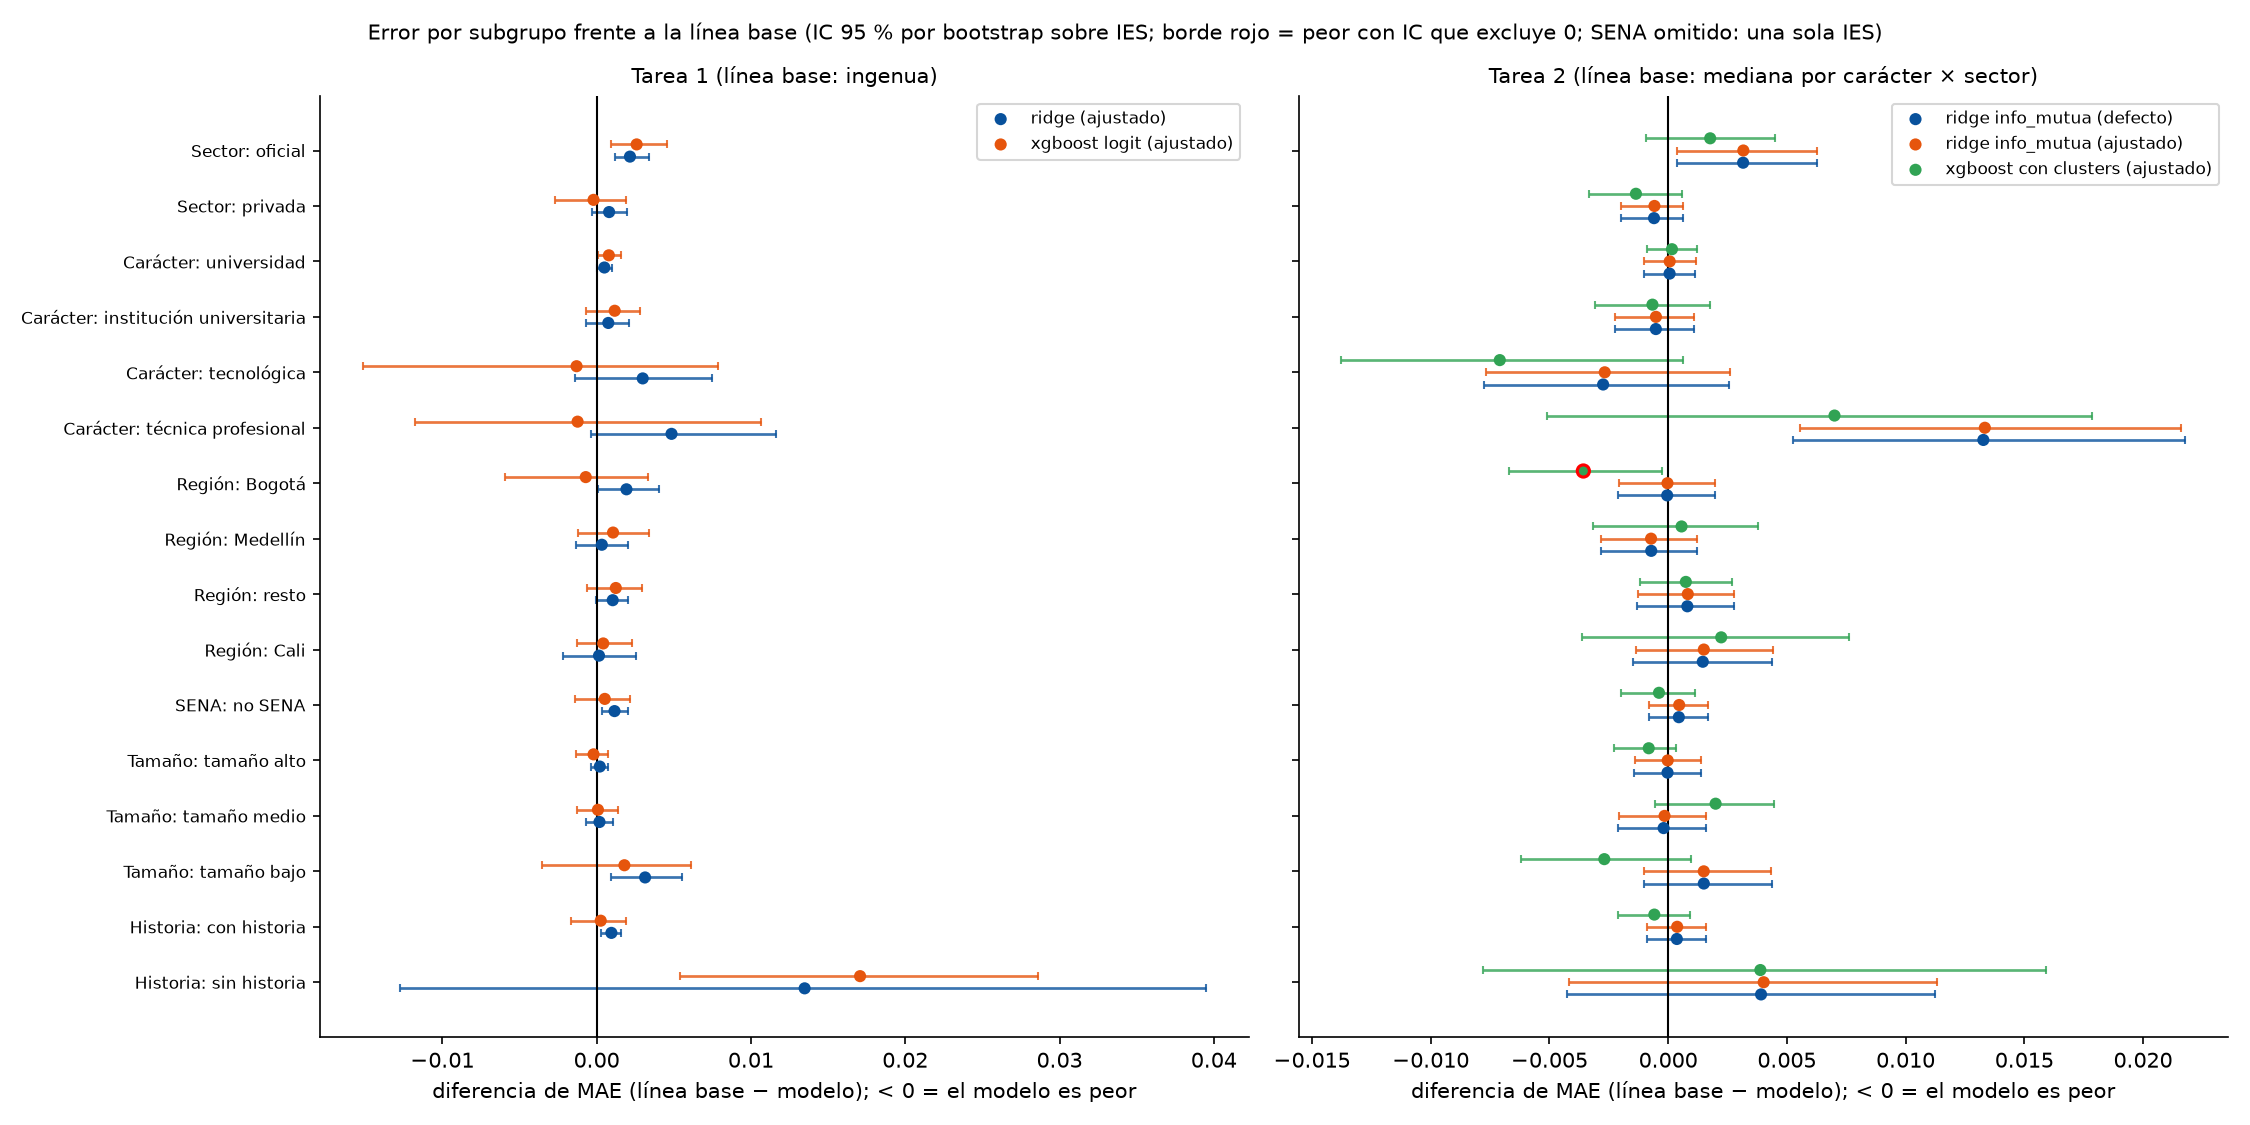

In [3]:
sub = pd.read_csv(R / "subgrupos.csv")
peores = sub[sub.clasificacion.str.startswith("peor")]
print("Subgrupos donde el modelo es peor que su línea base (con IC que excluye 0 → «peor que la línea base»; si no, «sin firmeza»):")
display(peores[["modelo", "variable", "nivel", "n_filas", "n_ies", "mae_modelo", "mae_base", "dif", "dif_ic_inf", "dif_ic_sup", "clasificacion"]].sort_values("dif").head(15).reset_index(drop=True))
display(Image("reports/figuras/error_subgrupos.png"))

In [4]:
# Verificación: el punto estimado de un subgrupo es el promedio, sobre las filas del subgrupo, del error medio de las 5 repeticiones
oof = np.load(R / "_parcial_sesgo" / "oof_base.npz") if (R / "_parcial_sesgo" / "oof_base.npz").exists() else None
if oof is not None:
    y = df.tasa_desercion.to_numpy()
    s_, _ = sg.asignar_subgrupos(df, p["ciudades"])
    m = (s_["region"] == "Bogotá").to_numpy()
    for modelo in ("T2 xgboost con clusters (ajustado)", "T2 base_mediana_grupo"):
        print(f"{modelo:40s} MAE en Bogotá = {np.abs(oof[modelo] - y).mean(axis=0)[m].mean():.4f}")
    fila = sub[(sub.modelo == "T2 xgboost con clusters (ajustado)") & (sub.variable == "region") & (sub.nivel == "Bogotá")].iloc[0]
    print("En subgrupos.csv: modelo", round(fila.mae_modelo, 4), "| línea base", round(fila.mae_base, 4), "| diferencia", round(fila.dif, 4), f"[{fila.dif_ic_inf:.4f}; {fila.dif_ic_sup:.4f}]")
else:
    print("Los puntos de control no están (data/ no se versiona): se omite la verificación.")

T2 xgboost con clusters (ajustado)       MAE en Bogotá = 0.0563
T2 base_mediana_grupo                    MAE en Bogotá = 0.0527
En subgrupos.csv: modelo 0.0563 | línea base 0.0527 | diferencia -0.0036 [-0.0067; -0.0002]


## 3. Sensibilidad

Se re-entrena todo con el mismo protocolo en el dataset ya construido (sin re-correr el ETL). Los hiperparámetros finales **no se re-ajustan** en cada escenario.
«Cambia la conclusión» = cambia la clase frente a la línea base (`supera`, `empeora` o `sin diferencia firme`, con significancia en Wilcoxon y t corregida).

In [5]:
sens = pd.read_csv(R / "sensibilidad.csv")
cols = ["escenario", "n_filas", "n_ies", "configuracion", "mae", "mae_ic_inf", "mae_ic_sup", "mejora_base_pct", "p_wilcoxon", "p_t_corregida", "clase", "cambia_conclusion"]
for tarea in ("T1", "T2"):
    print("Tarea", tarea[1])
    display(sens[sens.tarea == tarea][cols].reset_index(drop=True))

Tarea 1


,escenario,n_filas,n_ies,configuracion,mae,mae_ic_inf,mae_ic_sup,mejora_base_pct,p_wilcoxon,p_t_corregida,clase,cambia_conclusion
0,base,1928,295,T1 base_ingenua,0.0256,0.0225,0.0288,NaN,NaN,NaN,NaN,False
1,base,1928,295,T1 base_mediana,0.0501,0.0441,0.0560,NaN,NaN,NaN,NaN,False
2,base,1928,295,T1 C solo historia | ridge (ajustado),0.0245,0.0212,0.0277,4.6069,0.0000,0.0090,supera,False
3,base,1928,295,T1 B historia+contexto | xgboost logit (ajustado),0.0251,0.0212,0.0289,2.2017,0.1073,0.5874,sin diferencia firme,False
4,sin_bogota,1331,202,T1 base_ingenua,0.0229,0.0192,0.0265,NaN,NaN,NaN,NaN,False
5,sin_bogota,1331,202,T1 base_mediana,0.0430,0.0347,0.0513,NaN,NaN,NaN,NaN,False
6,sin_bogota,1331,202,T1 C solo historia | ridge (ajustado),0.0219,0.0188,0.0250,4.1526,0.0002,0.0970,sin diferencia firme,True
7,sin_bogota,1331,202,T1 B historia+contexto | xgboost logit (ajustado),0.0222,0.0187,0.0257,2.8623,0.0393,0.4188,sin diferencia firme,False
8,umbral_200,1846,281,T1 base_ingenua,0.0229,0.0195,0.0263,NaN,NaN,NaN,NaN,False
9,umbral_200,1846,281,T1 base_mediana,0.0469,0.0399,0.0539,NaN,NaN,NaN,NaN,False


Tarea 2


,escenario,n_filas,n_ies,configuracion,mae,mae_ic_inf,mae_ic_sup,mejora_base_pct,p_wilcoxon,p_t_corregida,clase,cambia_conclusion
0,base,1928,295,T2 base_mediana_grupo,0.0400,0.0345,0.0455,NaN,NaN,NaN,NaN,False
1,base,1928,295,T2 base_mediana,0.0501,0.0441,0.0560,NaN,NaN,NaN,NaN,False
2,base,1928,295,T2 ridge info_mutua (defecto),0.0396,0.0343,0.0448,1.0877,0.0903,0.5621,sin diferencia firme,False
3,base,1928,295,T2 ridge info_mutua (ajustado),0.0395,0.0343,0.0448,1.1275,0.0755,0.5449,sin diferencia firme,False
4,base,1928,295,T2 xgboost con clusters (ajustado),0.0405,0.0351,0.0459,-1.2239,0.2411,0.6372,sin diferencia firme,False
5,sin_bogota,1331,202,T2 base_mediana_grupo,0.0352,0.0302,0.0402,NaN,NaN,NaN,NaN,False
6,sin_bogota,1331,202,T2 base_mediana,0.0430,0.0347,0.0513,NaN,NaN,NaN,NaN,False
7,sin_bogota,1331,202,T2 ridge info_mutua (defecto),0.0339,0.0290,0.0387,3.7436,0.0187,0.4269,sin diferencia firme,False
8,sin_bogota,1331,202,T2 ridge info_mutua (ajustado),0.0338,0.0290,0.0386,3.9618,0.0187,0.4032,sin diferencia firme,False
9,sin_bogota,1331,202,T2 xgboost con clusters (ajustado),0.0336,0.0290,0.0381,4.6635,0.0012,0.1972,sin diferencia firme,False


## 4. Diagnóstico del colapso del ridge ajustado de la Tarea 2 (prepandemia)

Se entrena con 2015–2017 y se prueba en 2018–2019 con los hiperparámetros que la búsqueda interna eligió en esa partición. Se prueba si el colapso desaparece
(i) quitando `mpio_matriculados_t2`, (ii) con el alfa por defecto, (iii) recortando las variables escaladas a [-3, 3]; y (iv, adicional) entrenando solo con 2017.
Es solo diagnóstico: no cambia los modelos finales.

,variante,alpha,k,n_entrenamiento,selecciona_variable,coef_variable,mae,mae_2018,mae_2019,mae_bogota,mae_resto,peores_en_bogota
0,referencia,0.4374,20,833,True,0.4445,0.0642,0.0368,0.0918,0.1367,0.0318,39
1,i_sin_variable,0.4374,20,833,False,NaN,0.0407,0.0364,0.0450,0.0634,0.0305,31
2,ii_alfa_defecto,1.0000,20,833,True,0.3459,0.0554,0.0365,0.0746,0.1099,0.0311,37
3,ii_defecto_completo,3.1623,15,833,True,-0.0191,0.0360,0.0364,0.0355,0.0483,0.0305,20
4,iii_recorte,0.4374,20,833,True,0.5245,0.0728,0.0360,0.1099,0.1638,0.0321,39
5,iv_solo_2017,0.4374,20,274,True,0.2063,0.0507,0.0480,0.0535,0.0740,0.0403,28


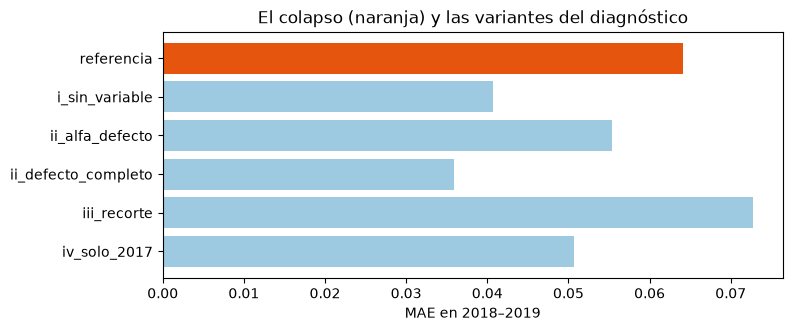

In [6]:
resumen, z, pe = dc.ejecutar_diagnostico(cfg, df)   # se recalcula aquí (≈2 s)
display(resumen[["variante", "alpha", "k", "n_entrenamiento", "selecciona_variable", "coef_variable", "mae", "mae_2018", "mae_2019", "mae_bogota", "mae_resto", "peores_en_bogota"]])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(resumen.variante[::-1], resumen.mae[::-1], color=["#9ecae1" if v != "referencia" else "#e6550d" for v in resumen.variante[::-1]])
ax.set_xlabel("MAE en 2018–2019"); ax.set_title("El colapso (naranja) y las variantes del diagnóstico"); plt.show()

In [7]:
# z de las variables respecto del entrenamiento y las filas de mayor error (municipio incluido)
print("Variables con mayor |z| en la prueba, y la variable sospechosa:")
display(pd.concat([z.head(6), z[z.variable == "mpio_matriculados_t2"]]).drop_duplicates("variable")[["variable", "seleccionada", "coef", "z_max_abs", "z_max_abs_bogota", "pct_filas_z_sobre_umbral", "pct_bogota_fuera_del_rango"]])
print("Las 8 filas de mayor error:")
display(pe.head(8)[["rango", "cod_ies", "municipio", "anio", "caracter", "y", "pred", "error", "z_variable_sospechosa", "aporte_variable_sospechosa"]])
print("Municipios de las", len(pe), "filas de mayor error:", pe.municipio.value_counts().to_dict())

Variables con mayor |z| en la prueba, y la variable sospechosa:


,variable,seleccionada,coef,z_max_abs,z_max_abs_bogota,pct_filas_z_sobre_umbral,pct_bogota_fuera_del_rango
0,td_idf_deuda_t1,True,-0.0367,13.1069,0.8081,1.9964,0.0000
1,td_mdm_educacion_t1,False,0.0000,9.8147,0.2498,11.0708,0.0000
2,td_cob_bruta_media_t1,True,-0.0999,7.7395,0.3557,0.7260,0.0000
3,td_mdm_resultados_t1,False,0.0000,7.6246,4.2693,49.3648,0.0000
4,td_pct_pob_20_24_t1,False,0.0000,7.2717,1.2630,0.3630,0.0000
5,td_nbi_pct_t1,True,-0.0842,6.6753,0.5979,1.8149,0.0000
29,mpio_matriculados_t2,True,0.4445,1.7902,1.7902,0.0000,100.0000


Las 8 filas de mayor error:


,rango,cod_ies,municipio,anio,caracter,y,pred,error,z_variable_sospechosa,aporte_variable_sospechosa
0,1,9903,11001,2018,tecnológica,0.7918,0.2461,0.5457,1.7306,0.7693
1,2,9903,11001,2019,tecnológica,0.9942,0.5159,0.4783,1.7902,0.7958
2,3,3809,11001,2019,tecnológica,0.0938,0.5215,0.4278,1.7902,0.7958
3,4,4726,11001,2019,técnica profesional,0.1718,0.5428,0.3710,1.7902,0.7958
4,5,4813,11001,2019,técnica profesional,0.1499,0.5191,0.3692,1.7902,0.7958
5,6,3702,11001,2019,tecnológica,0.1425,0.5059,0.3634,1.7902,0.7958
6,7,3808,11001,2019,tecnológica,0.1467,0.5072,0.3605,1.7902,0.7958
7,8,3725,11001,2019,tecnológica,0.1582,0.5097,0.3516,1.7902,0.7958


Municipios de las 40 filas de mayor error: {'11001': 39, '76001': 1}


## 5. Interpretabilidad

- **SHAP** (`TreeExplainer`) en los dos xgboost finales, ajustados con todo el dataset. xgboost se entrena sobre el logit de la tasa: SHAP positivo = sube la deserción predicha.
- **Importancia por permutación** en validación (GroupKFold por IES): aumento del MAE al permutar cada variable original.
- **Coeficientes del ridge** y su estabilidad en los 25 pliegues de entrenamiento.

T1 B historia+contexto | xgboost logit (ajustado)


,rank,variable,mean_abs_shap,spearman
0,1,tasa_t1,0.2676,0.9969
1,2,tasa_t2,0.0908,0.9840
2,3,tasa_media_previa,0.0404,0.8642
3,4,log_matriculados_spadies_t2,0.0151,-0.4863
4,5,n_anios_previos,0.0130,-0.6549
5,6,caracter_universidad,0.0044,-0.9035
6,7,caracter_tecnológica,0.0040,0.5629
7,8,caracter_técnica profesional,0.0032,0.4602
8,9,falta_historia,0.0023,0.2350
9,10,mpio_ies_con_oferta_t2,0.0012,0.7755


T2 xgboost con clusters (ajustado)


,rank,variable,mean_abs_shap,spearman
0,1,caracter_universidad,0.2214,-0.8682
1,2,log_matriculados_spadies_t2,0.1150,-0.4821
2,3,caracter_institución universitaria,0.0920,-0.8782
3,4,caracter_técnica profesional,0.0472,0.4375
4,5,td_pct_poblacion_rural_t1,0.0381,-0.8143
5,6,caracter_tecnológica,0.0313,0.5569
6,7,sector_oficial,0.0212,-0.7836
7,8,td_miseria_pct_t1,0.0186,0.7131
8,9,distancia_cluster_5,0.0157,0.7093
9,10,td_pct_pob_20_24_t1,0.0144,0.5707


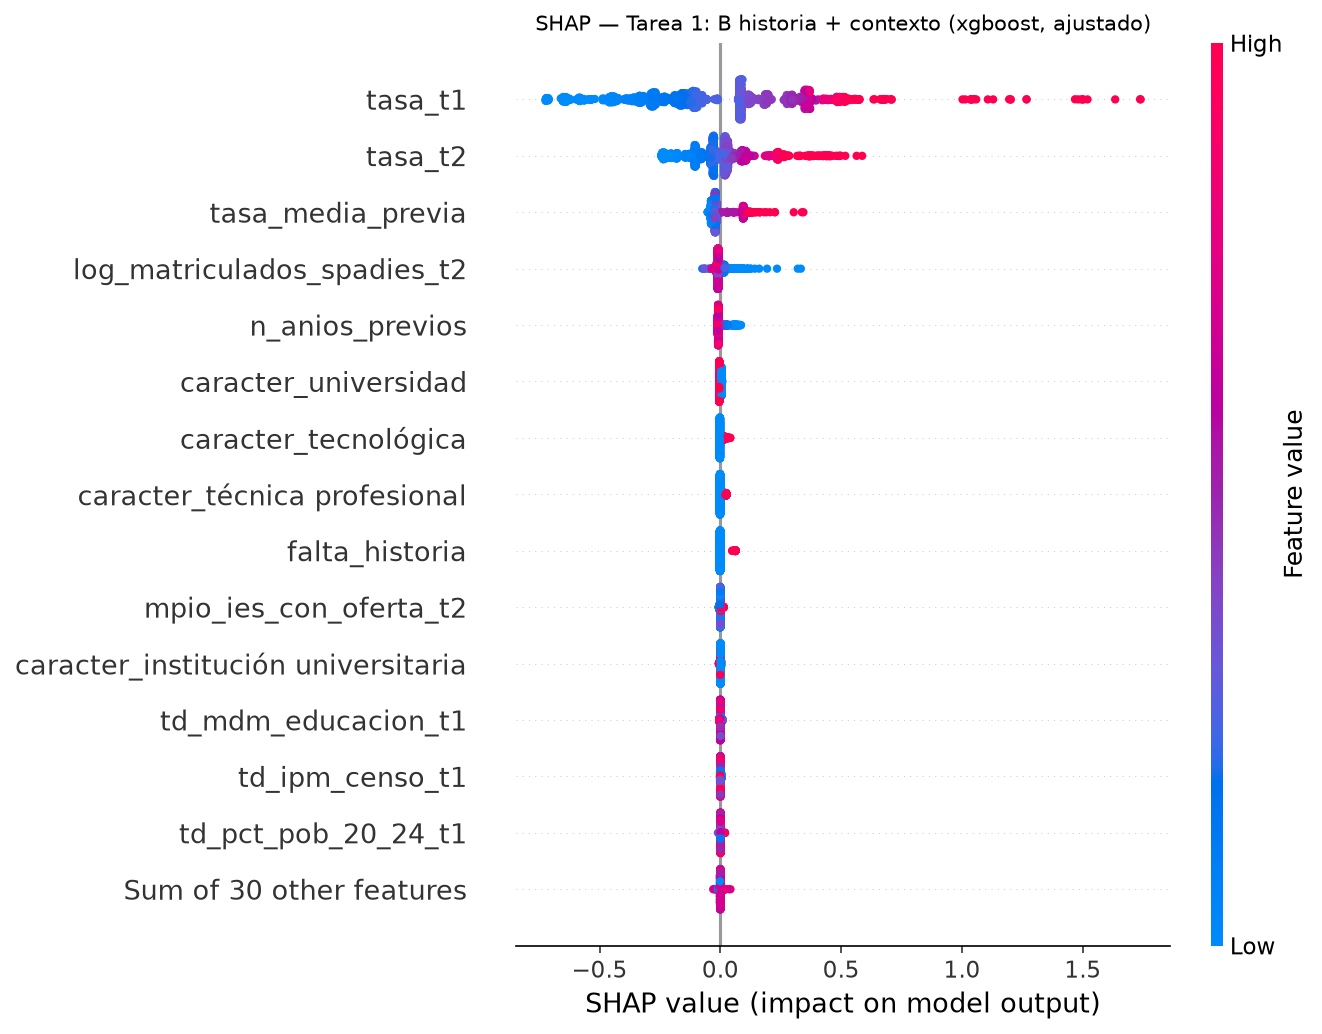

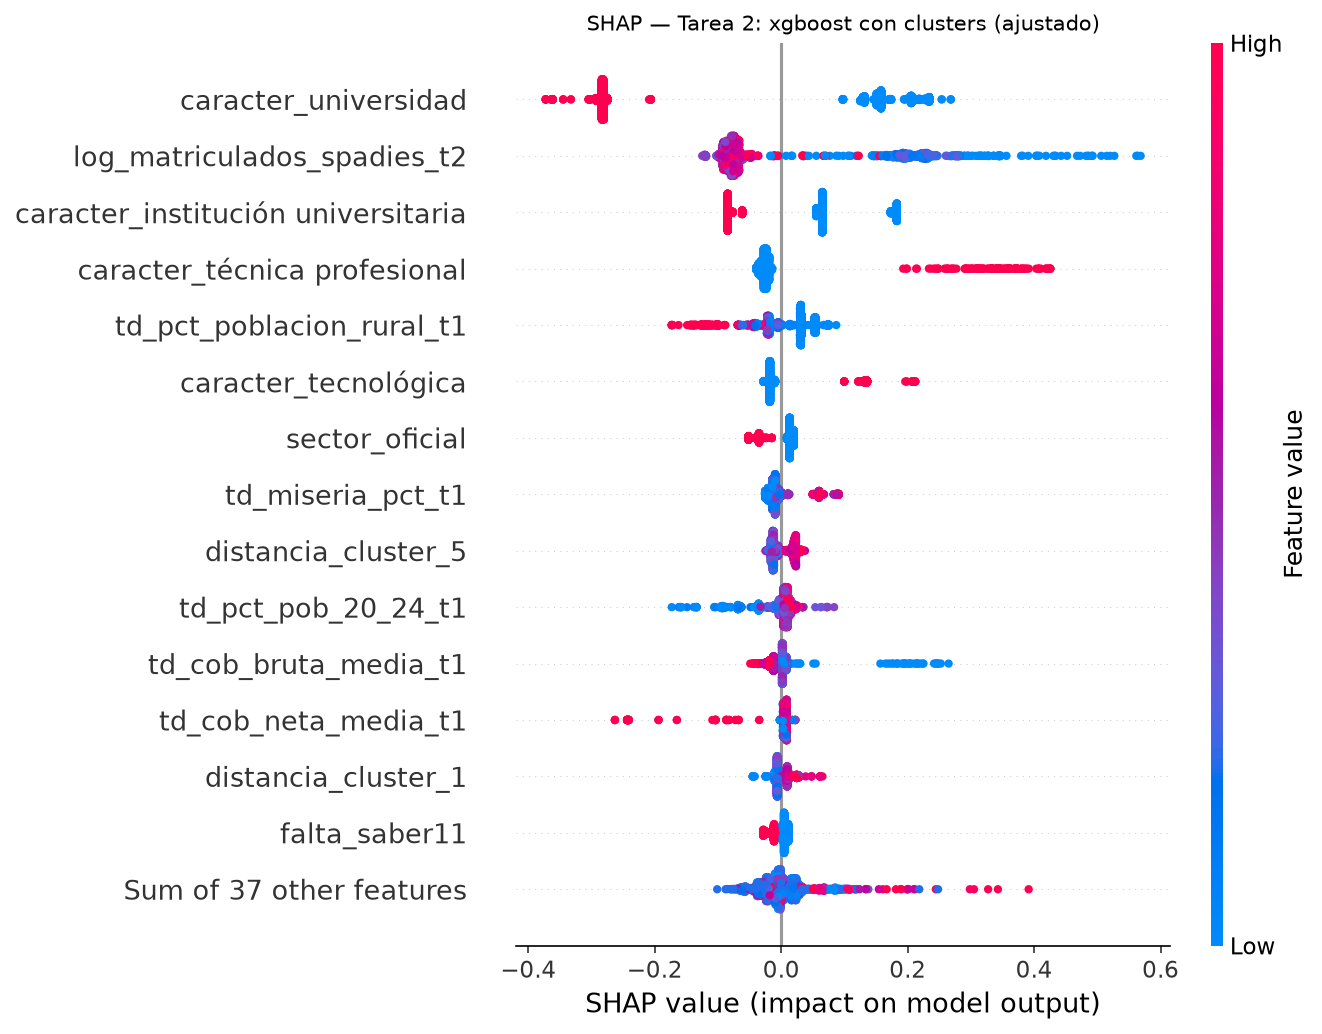

In [8]:
top = pd.read_csv(R / "shap_top.csv")
for modelo, g in top.groupby("modelo", sort=False):
    print(modelo)
    display(g[["rank", "variable", "mean_abs_shap", "spearman"]].reset_index(drop=True))
display(Image("reports/figuras/shap_t1.png"))
display(Image("reports/figuras/shap_t2.png"))

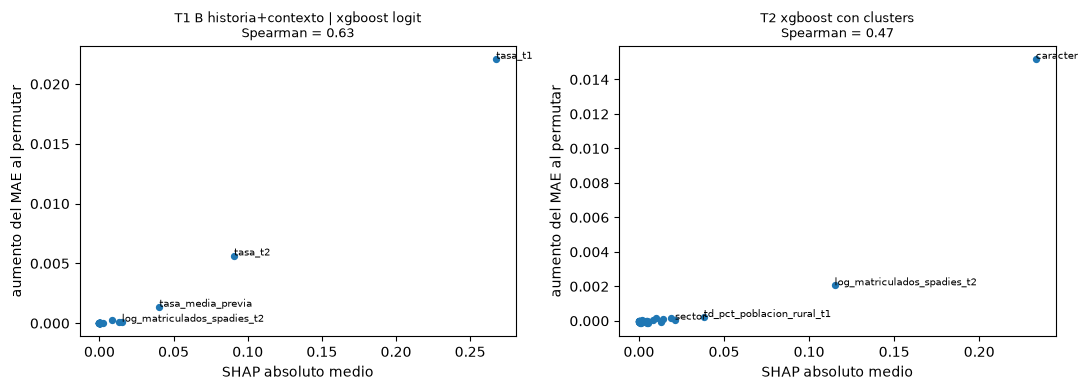

In [9]:
# ¿Coinciden SHAP y permutación? Orden por variable original (los clusters, derivados de todas las variables, quedan aparte)
gr = pd.read_csv(R / "shap_grupos.csv")
from scipy.stats import spearmanr
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (modelo, g) in zip(ejes, gr[gr.variable != "clusters (agregados)"].dropna(subset=["rank_permutacion"]).groupby("modelo", sort=False)):
    rho = spearmanr(g.mean_abs_shap, g.aumento_mae_medio).statistic
    ax.scatter(g.mean_abs_shap, g.aumento_mae_medio, s=18)
    for _, r in g.sort_values("mean_abs_shap", ascending=False).head(4).iterrows():
        ax.annotate(r.variable, (r.mean_abs_shap, r.aumento_mae_medio), fontsize=7)
    ax.set_xlabel("SHAP absoluto medio"); ax.set_ylabel("aumento del MAE al permutar"); ax.set_title(f"{modelo.split(' (')[0]}\nSpearman = {rho:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

,modelo,variable,n_pliegues_seleccionada,de_pliegues,media,desviacion,signo_constante
0,T2 ridge info_mutua (ajustado),caracter_técnica profesional,25,25,0.5764,0.0987,True
1,T2 ridge info_mutua (ajustado),caracter_universidad,25,25,-0.5320,0.1035,True
2,T2 ridge info_mutua (ajustado),caracter_tecnológica,25,25,0.3463,0.0991,True
3,T2 ridge info_mutua (ajustado),caracter_institución universitaria,21,25,-0.2725,0.0265,True
4,T2 ridge info_mutua (ajustado),td_miseria_pct_t1,25,25,0.1296,0.0217,True
5,T2 ridge info_mutua (ajustado),log_matriculados_spadies_t2,25,25,-0.0923,0.0173,True
6,T2 ridge info_mutua (ajustado),td_nbi_pct_t1,25,25,-0.0756,0.0301,True
7,T2 ridge info_mutua (ajustado),td_idf_transferencias_t1,17,25,-0.0592,0.0249,True
8,T2 ridge info_mutua (ajustado),td_pct_pob_15_19_t1,1,25,0.0539,NaN,True
9,T2 ridge info_mutua (ajustado),td_idf_inversion_t1,1,25,-0.0534,NaN,True


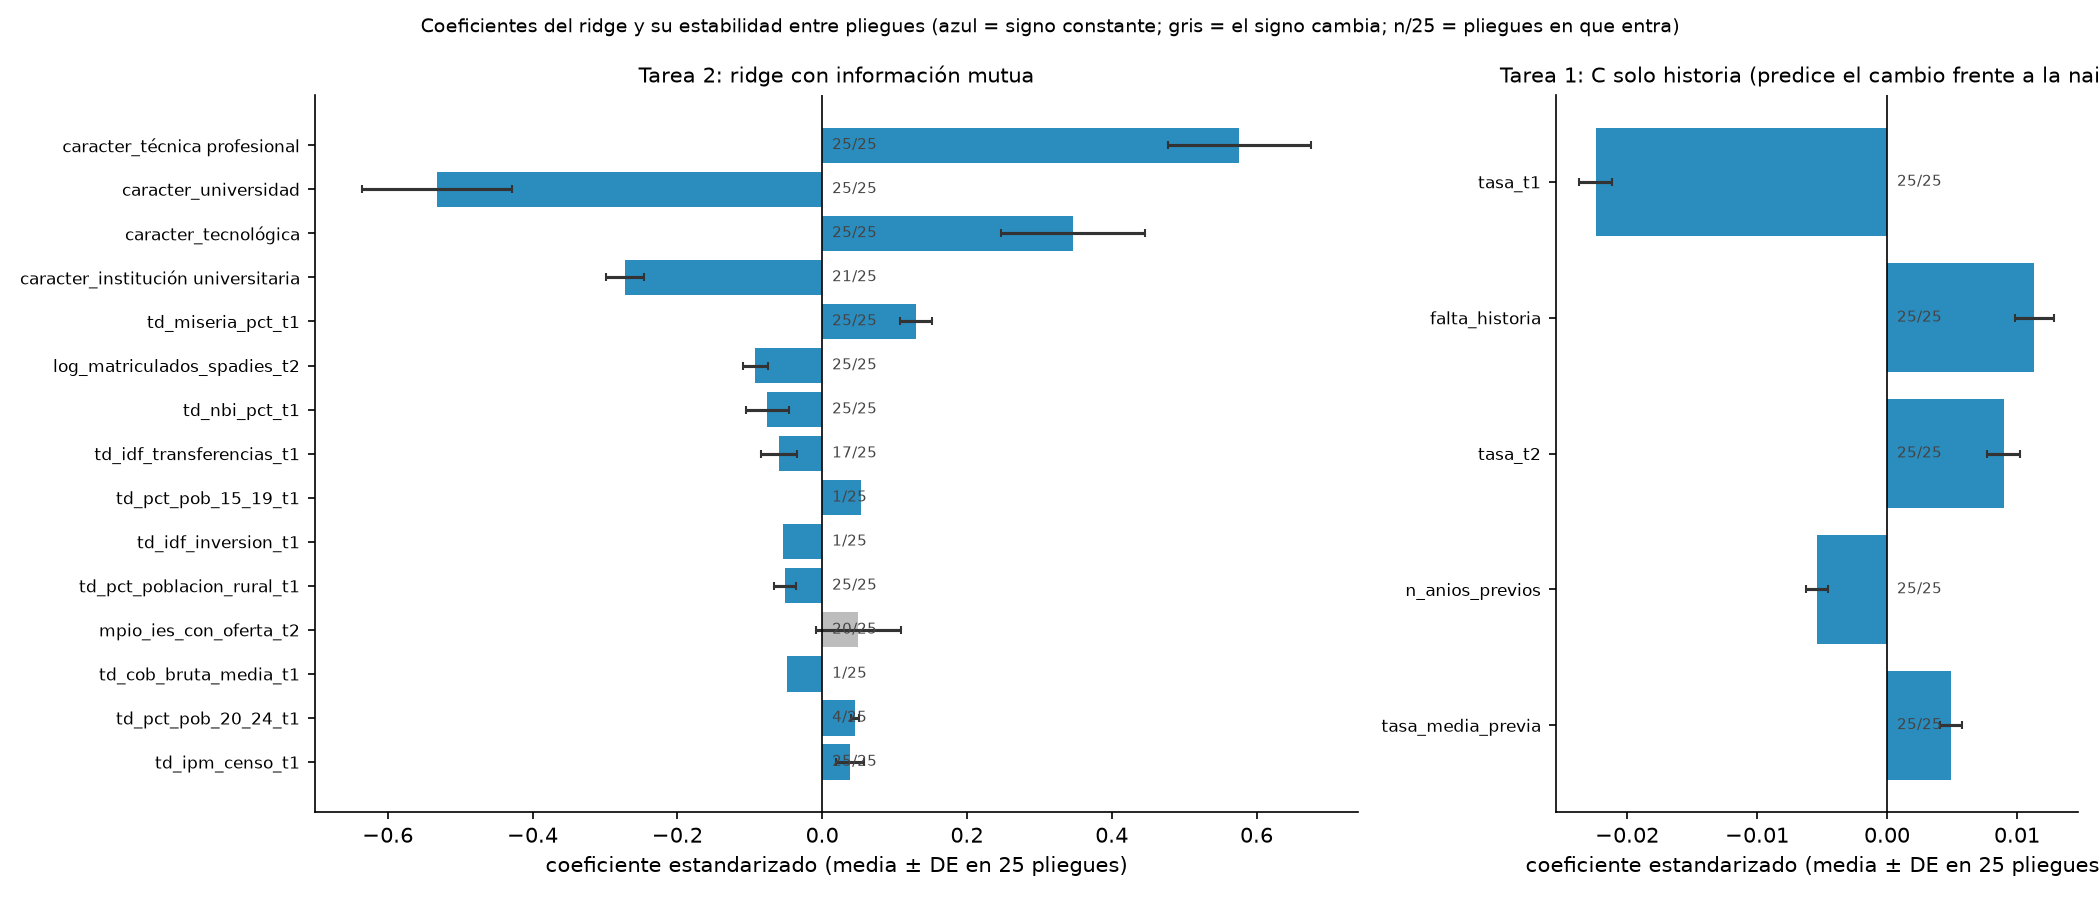

In [10]:
# Coeficientes del ridge de la Tarea 2 (información mutua): estabilidad entre los 25 pliegues
coef = pd.read_csv(R / "coeficientes_ridge.csv")
display(coef[coef.modelo.str.startswith("T2")].head(12))
display(Image("reports/figuras/coeficientes_ridge.png"))

## 6. Conclusiones

(Tomadas de `reports/resultados_sesgo_sensibilidad.md`; todas las cifras salen de la corrida. La tabla «en lenguaje simple» con la dirección de cada variable y la coincidencia entre métodos está en ese informe.)

**1. ¿Qué subgrupos quedan peor servidos?** Con IC 95 % por bootstrap sobre IES; «peor» = el modelo tiene más error que su línea base.
  - `T1 C solo historia | ridge (ajustado)`: peor que su línea base con IC que excluye 0 en ningún subgrupo; peor sin firmeza (n ≥ 30) en ningún subgrupo.
  - `T1 B historia+contexto | xgboost logit (ajustado)`: peor que su línea base con IC que excluye 0 en ningún subgrupo; peor sin firmeza (n ≥ 30) en sector: privada (-0,0002), caracter: tecnológica (-0,0013), caracter: técnica profesional (-0,0012), region: Bogotá (-0,0007), tamano: tamaño alto (-0,0002).
  - `T2 ridge info_mutua (defecto)`: peor que su línea base con IC que excluye 0 en ningún subgrupo; peor sin firmeza (n ≥ 30) en sector: privada (-0,0006), caracter: institución universitaria (-0,0005), caracter: tecnológica (-0,0027), region: Bogotá (-0,0000), region: Medellín (-0,0007), tamano: tamaño alto (-0,0000), tamano: tamaño medio (-0,0002).
  - `T2 ridge info_mutua (ajustado)`: peor que su línea base con IC que excluye 0 en ningún subgrupo; peor sin firmeza (n ≥ 30) en sector: privada (-0,0006), caracter: institución universitaria (-0,0005), caracter: tecnológica (-0,0027), region: Bogotá (-0,0000), region: Medellín (-0,0007), tamano: tamaño alto (-0,0000), tamano: tamaño medio (-0,0002).
  - `T2 xgboost con clusters (ajustado)`: peor que su línea base con IC que excluye 0 en region: Bogotá (-0,0036 [-0,0067; -0,0002], 597 filas); peor sin firmeza (n ≥ 30) en sector: privada (-0,0014), caracter: institución universitaria (-0,0007), caracter: tecnológica (-0,0071), es_sena: no SENA (-0,0004), tamano: tamaño alto (-0,0008), tamano: tamaño bajo (-0,0027), falta_historia: con historia (-0,0006).
- Con más error absoluto (modelo con menos error de cada tarea): Tarea 1 `T1 C solo historia | ridge (ajustado)`: falta_historia: sin historia (MAE 0,1137; línea base 0,1271; 34 filas), caracter: técnica profesional (MAE 0,0548; línea base 0,0596; 132 filas), caracter: tecnológica (MAE 0,0541; línea base 0,0571; 218 filas). Tarea 2 `T2 ridge info_mutua (ajustado)`: falta_historia: sin historia (MAE 0,1072; línea base 0,1112; 34 filas), caracter: tecnológica (MAE 0,0781; línea base 0,0754; 218 filas), caracter: técnica profesional (MAE 0,0781; línea base 0,0914; 132 filas).

**2. ¿Alguna sensibilidad cambia la conclusión?** («Cambia» = cambia la clase frente a la línea base —`supera`, `empeora` o `sin diferencia firme`, con significancia en las dos pruebas— respecto del escenario base.)
- Escenario `sin_bogota`, `T1 C solo historia | ridge (ajustado)`: de «supera» a «sin diferencia firme» (mejora frente a la línea base +4,6 % en el dataset completo y +4,2 % en el escenario; p Wilcoxon < 0,001, p t corregida 0,097).
- Escenario `umbral_200`, `T1 B historia+contexto | xgboost logit (ajustado)`: de «sin diferencia firme» a «supera» (mejora frente a la línea base +2,2 % en el dataset completo y +5,3 % en el escenario; p Wilcoxon < 0,001, p t corregida 0,036).
- Escenario `umbral_200`, `T2 ridge info_mutua (defecto)`: de «sin diferencia firme» a «supera» (mejora frente a la línea base +1,1 % en el dataset completo y +4,1 % en el escenario; p Wilcoxon < 0,001, p t corregida 0,039).
- Escenario `umbral_200`, `T2 ridge info_mutua (ajustado)`: de «sin diferencia firme» a «supera» (mejora frente a la línea base +1,1 % en el dataset completo y +4,2 % en el escenario; p Wilcoxon < 0,001, p t corregida 0,039).
- Escenario `desde_2017`, `T1 C solo historia | ridge (ajustado)`: de «supera» a «sin diferencia firme» (mejora frente a la línea base +4,6 % en el dataset completo y +4,3 % en el escenario; p Wilcoxon < 0,001, p t corregida 0,117).
- **Hipótesis del SNIES imputado en 2015–2016** (escenario 2017–2021, solo con matrícula SNIES observada): mejora de los modelos de la Tarea 2 frente a la mediana por carácter × sector, dataset completo → 2017–2021: `T2 ridge info_mutua (defecto)`: +1,1 % → +1,8 %; `T2 ridge info_mutua (ajustado)`: +1,1 % → +1,9 %; `T2 xgboost con clusters (ajustado)`: -1,2 % → -2,4 %.

**3. ¿Se confirma la causa del colapso?** (ridge ajustado de la Tarea 2, partición prepandemia; «exceso» = MAE de la referencia − MAE de la configuración por defecto)
- Se reproduce el colapso: MAE 0,0642 frente a 0,0360 por defecto (exceso 0,0282); por año, 2018: 0,0368 y 2019: 0,0918. 39 de las 40 filas de mayor error son de Bogotá (MAE en Bogotá 0,1367 frente a 0,0318 en el resto).
- **(i) Quitar `mpio_matriculados_t2`:** MAE 0,0407, elimina 83 % del exceso. Esa variable explica la mayor parte del colapso.
- **(ii) Alfa por defecto:** con `RidgeCV` y el mismo k, MAE 0,0554 (elimina 31 %); con la configuración por defecto completa (k = 15) el coeficiente de la variable es -0,019 frente a 0,445 en la referencia: con poca regularización y k = 20 el modelo le da un peso grande.
- **(iii) Recortar las variables escaladas a [-3, 3]:** MAE 0,0728 (-30 % del exceso). El recorte no corrige el colapso: no se debe a valores extremos (|z| > 3).
- **(iv, adicional) Entrenar solo con 2017** (único año con SNIES observado): MAE 0,0507 (48 % del exceso; 274 filas de entrenamiento). Con SNIES observado el colapso persiste: la hipótesis del SNIES imputado no se sostiene como causa principal.
- **Respuesta:** se confirma una causa **específica de una variable** (`mpio_matriculados_t2` con un coeficiente grande), no una extrapolación a valores extremos ni, por sí sola, la imputación del SNIES; el detalle de z por variable y las filas de mayor error está en las tablas de abajo y en `colapso_ridge_z.csv` y `colapso_ridge_peores.csv`.

**4. ¿Qué variables usan los modelos y coinciden los métodos?**
- **Tarea 1, B xgboost.** Top 5 por |SHAP|: `tasa_t1` (0,268), `tasa_t2` (0,091), `tasa_media_previa` (0,040), `log_matriculados_spadies_t2` (0,015), `n_anios_previos` (0,013). Frente a la importancia por permutación: Spearman entre los órdenes 0,63 (40 variables originales), 4 de 5 variables en común en el top 5.
- **Tarea 2, xgboost con clusters.** Top 5 por |SHAP|: `caracter_universidad` (0,221), `log_matriculados_spadies_t2` (0,115), `caracter_institución universitaria` (0,092), `caracter_técnica profesional` (0,047), `td_pct_poblacion_rural_t1` (0,038). Frente a la importancia por permutación: Spearman entre los órdenes 0,47 (35 variables originales), 4 de 5 variables en común en el top 5.
- **Ridge de la Tarea 2:** 10 de 27 variables que entran en al menos un pliegue lo hacen en la mitad o más con signo constante; las mayores: `caracter_técnica profesional` (0,576), `caracter_universidad` (-0,532), `caracter_tecnológica` (0,346), `caracter_institución universitaria` (-0,273).